### MLOps AIMLCZG523
### Assignment 2

#### LLMOps: API Cost, Latency and Prompt Version Management


|Name|BITS ID|
|---|---|
|Devang Ajay Kamble | 2025AE05173 |

#### Pre-requisites

We would be using Python 3.10 and the following libraries:
- mlflow==3.17.1
- openai==3.42.0
- pandas==2.3.3
- numpy==2.2.6
- matplotlib==3.10.9
- python-dotenv==1.2.4

Secrets are never written in the notebook. The API key and model settings are read from environment variables (or a git-ignored `.env` file): `LLM_API_KEY`, `LLM_BASE_URL`, `LLM_MODEL`, `INPUT_PRICE_PER_M`, `OUTPUT_PRICE_PER_M`, `PRICING_DATE`. See `README.md` for setup.

Scenario: EduAssist AI needs an academic Q&A assistant that returns strict JSON. We call an LLM with three prompt versions, measure latency and token cost, look at what that means for a real service at scale, and promote the best version in MLflow.

#### Imports and configuration

In [1]:
import difflib
import json
import os
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from mlflow import MlflowClient
from openai import OpenAI

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
load_dotenv(ROOT / ".env")

API_KEY = os.getenv("LLM_API_KEY") or os.getenv("OPENAI_API_KEY")
BASE_URL = os.getenv("LLM_BASE_URL") or None
MODEL = os.getenv("LLM_MODEL", "gpt-4o-mini")
API_VERSION = os.getenv("LLM_API_VERSION", "OpenAI Chat Completions API")
TEMPERATURE, MAX_TOKENS = 0.0, 1024
REPEATS = 3  # every version x question pair is sent this many times

# published prices per 1M tokens (USD); the price page and date are recorded in the report
IN_PRICE = float(os.getenv("INPUT_PRICE_PER_M", "0.3"))
OUT_PRICE = float(os.getenv("OUTPUT_PRICE_PER_M", "2.5"))
PRICING_DATE = os.getenv("PRICING_DATE", "2026-11-03")
CURRENCY = "USD"
MONTHLY_REQUESTS = 10_000  # the volume fixed by the brief

# business and scale ASSUMPTIONS (illustrative, not measured): change them to fit your own scenario
SLA_SECONDS = 2.0  # interactive-chat latency target
SCALE_VOLUMES = {'Baseline (brief)': 10000, 'Exam season': 100000, 'Campus-wide': 1000000}
PEAK_RPS = 5.0  # requests per second at the busiest moment
PRICE_MULTIPLIERS = [0.5, 1, 2, 4]  # what-if: model price relative to today's

EXPERIMENT = "eduassist_llmops_assignment"
PROMPT_NAME = "eduassist-qa-prompt"
CALLS_CSV = OUT / "latency_tokens_cost.csv"
EVAL_CSV = OUT / "prompt_evaluation_results.csv"

print("Model        :", MODEL)
print("API          :", API_VERSION)
print(f"Pricing      : {IN_PRICE} in / {OUT_PRICE} out {CURRENCY} per 1M tokens (checked {PRICING_DATE})")
print("Repeats      :", REPEATS)
print("API key set  :", bool(API_KEY))

Model        : gemini-3.5-flash-lite
API          : Gemini API v1beta (OpenAI-compatible endpoint)
Pricing      : 0.3 in / 2.5 out USD per 1M tokens (checked 2026-11-03)
Repeats      : 3
API key set  : True


#### Questions and prompt versions

Below are the 5 academic questions we will use for the experiment. Every prompt version gets the same questions, so differences come from the prompt and not from the input.

|ID|Category|Question|
|---|---|---|
|Q1|Definition|What does the F1 score measure, and when should it be preferred over accuracy?|
|Q2|Debugging|A neural network's training loss keeps falling but its validation loss starts rising after epoch 12. What is happening, and how can it be fixed?|
|Q3|MLOps scenario|A fraud-detection model had 95% accuracy at launch but performs much worse six months later. What are data drift and concept drift, and what should the team monitor to catch them?|
|Q4|Architecture|Why do LSTMs handle long sequences better than simple RNNs?|
|Q5|LLMOps economics|Why does the cost of an LLM application grow with prompt length, and how can a team keep it under control at scale?|

`{{question}}` below is the MLflow template variable.


With each prompt version, we make the prompt more and more descriptive of how we want the answer.

In [2]:
QUESTIONS = {
    'Q1': 'What does the F1 score measure, and when should it be preferred over accuracy?',
    'Q2': "A neural network's training loss keeps falling but its validation loss starts rising after epoch 12. What is happening, and how can it be fixed?",
    'Q3': 'A fraud-detection model had 95% accuracy at launch but performs much worse six months later. What are data drift and concept drift, and what should the team monitor to catch them?',
    'Q4': 'Why do LSTMs handle long sequences better than simple RNNs?',
    'Q5': 'Why does the cost of an LLM application grow with prompt length, and how can a team keep it under control at scale?',
}

QUESTION_META = {
    'Q1': dict(category='Definition'),
    'Q2': dict(category='Debugging'),
    'Q3': dict(category='MLOps scenario'),
    'Q4': dict(category='Architecture'),
    'Q5': dict(category='LLMOps economics'),
}

PROMPT_V1 = """Answer the following student question clearly.
Question: {{question}}"""

PROMPT_V2 = """You are an academic assistant.
Answer the following student question in a clear, concise, and accurate manner.
Use simple language suitable for undergraduate students.
Question: {{question}}"""

PROMPT_V3 = """You are an academic assistant.
Answer the student question and return ONLY valid JSON.
Do not include markdown, explanations outside JSON, or code fences.
Use this exact JSON schema:
{
  "answer": "string",
  "confidence": "high | medium | low",
  "key_points": ["string"]
}
Question: {{question}}"""

PROMPTS = {
    "v1": dict(template=PROMPT_V1, style="Basic",
               commit="v1 Basic: bare instruction, no role, no format or audience guidance (baseline)."),
    "v2": dict(template=PROMPT_V2, style="Structured",
               commit="v2 Structured: adds academic-assistant role and clear/concise/simple-language constraints."),
    "v3": dict(template=PROMPT_V3, style="JSON Output",
               commit="v3 JSON Output: adds strict JSON-only output with answer/confidence/key_points schema."),
}


def render(template, question):
    return template.replace("{{question}}", question)


print(render(PROMPT_V2, QUESTIONS["Q1"]))

You are an academic assistant.
Answer the following student question in a clear, concise, and accurate manner.
Use simple language suitable for undergraduate students.
Question: What does the F1 score measure, and when should it be preferred over accuracy?


#### JSON validity check

The `valid_json` metric is strict on purpose. The raw response must parse as JSON and match the schema exactly: keys `answer`, `confidence`, `key_points`, with `confidence` limited to high / medium / low. Anything else would fail

In [3]:
def is_valid_json(text):
    # strict: raw text must parse and match the schema, no fences or extra prose
    try:
        obj = json.loads(text)
    except (TypeError, ValueError):
        return False
    return (isinstance(obj, dict)
            and set(obj) == {"answer", "confidence", "key_points"}
            and isinstance(obj["answer"], str)
            and obj["confidence"] in {"high", "medium", "low"}
            and isinstance(obj["key_points"], list)
            and all(isinstance(k, str) for k in obj["key_points"]))


good = '{"answer": "x", "confidence": "high", "key_points": ["a"]}'
print("plain JSON  :", is_valid_json(good))
print("code fence  :", is_valid_json("```json\n" + good + "\n```"))
print("prose first :", is_valid_json("Sure! " + good))
print("bad schema  :", is_valid_json('{"answer": "x"}'))

plain JSON  : True
code fence  : False
prose first : False
bad schema  : False


Result

* Only the plain, schema-conforming JSON passes. The fenced, prose-prefixed and incomplete replies are all rejected, so `valid_json` will not be flattered by sloppy formatting.

### Task-1: Call an LLM and Measure Latency

#### API call function

One function sends a prompt and returns everything Task 1 and Task 2 need: start and end time, latency, status, response text and token usage. Latency is timed with a monotonic clock around the API call only. Local processing is excluded. The key comes from the environment, and any API failure is recorded as `status = "error"` instead of crashing the run (it is retried with a growing delay first).

In [4]:
def now():
    return datetime.now(timezone.utc).isoformat(timespec="milliseconds")


def call_llm(prompt, retries=4):
    if not API_KEY:
        raise RuntimeError("Set LLM_API_KEY in your environment or .env file")
    client = OpenAI(api_key=API_KEY, base_url=BASE_URL)
    for attempt in range(retries + 1):
        start, t0 = now(), time.perf_counter()
        try:
            r = client.chat.completions.create(
                model=MODEL, temperature=TEMPERATURE, max_tokens=MAX_TOKENS,
                messages=[{"role": "user", "content": prompt}])
            return dict(start_time=start, end_time=now(), latency_seconds=time.perf_counter() - t0,
                        status="success", response_text=r.choices[0].message.content or "",
                        input_tokens=r.usage.prompt_tokens, output_tokens=r.usage.completion_tokens,
                        total_tokens=r.usage.total_tokens, error="")
        except Exception as exc:  # record any API failure in the log
            failure = dict(start_time=start, end_time=now(), latency_seconds=time.perf_counter() - t0,
                           status="error", response_text="", input_tokens=0, output_tokens=0,
                           total_tokens=0, error=f"{type(exc).__name__}: {exc}")
            time.sleep(2 ** attempt)
    return failure

#### Run the requests

Each of the three prompt versions is sent each of the five questions 3 times: 5 x 3 x 3 = 45 requests. The repeats are interleaved (repeat, then version, then question) so a slow period on the provider's side hits every version alike instead of penalising whichever one happened to run then.

Task 1 reports the five `v1` requests of the first repeat, as the brief asks. The repeats are used afterwards to measure how noisy latency really is, and Tasks 2 and 3 average over all of them, so every number in this notebook comes from one set of API calls. Cost, tokens per second, answer length and key-point count are added to each row.

The cell below makes the requests (a few minutes) and saves the log to `outputs/latency_tokens_cost.csv`.

In [5]:
def input_cost(tokens):
    return tokens / 1_000_000 * IN_PRICE


def output_cost(tokens):
    return tokens / 1_000_000 * OUT_PRICE


def key_point_count(text):
    try:
        return len(json.loads(text)["key_points"])
    except (TypeError, ValueError, KeyError):
        return np.nan


def collect_calls():
    rows = []
    for rep in range(1, REPEATS + 1):
        for version, p in PROMPTS.items():
            for qid, question in QUESTIONS.items():
                r = call_llm(render(p["template"], question))
                ic, oc = input_cost(r["input_tokens"]), output_cost(r["output_tokens"])
                rows.append(dict(repeat=rep, question_id=qid, prompt_version=version, model=MODEL,
                                 start_time=r["start_time"], end_time=r["end_time"],
                                 latency_seconds=round(r["latency_seconds"], 4), status=r["status"],
                                 input_tokens=r["input_tokens"], output_tokens=r["output_tokens"],
                                 total_tokens=r["total_tokens"], input_cost=ic, output_cost=oc,
                                 total_cost=ic + oc,
                                 tokens_per_second=r["output_tokens"] / r["latency_seconds"],
                                 answer_words=len(r["response_text"].split()),
                                 key_points=key_point_count(r["response_text"]),
                                 valid_json=is_valid_json(r["response_text"]),
                                 response_text=r["response_text"], error=r["error"]))
                print(f"rep{rep} {version} {qid}: {r['status']:7s} {r['latency_seconds']:.2f}s "
                      f"in={r['input_tokens']} out={r['output_tokens']}")
    df = pd.DataFrame(rows)
    df.to_csv(CALLS_CSV, index=False)
    return df


df = collect_calls()

print("Shape    :", df.shape)
print("Status   :", df["status"].value_counts().to_dict())
df.drop(columns=["response_text", "error"]).head()

Shape    : (45, 20)
Status   : {'success': 45}


,repeat,question_id,prompt_version,model,start_time,end_time,latency_seconds,status,input_tokens,output_tokens,total_tokens,input_cost,output_cost,total_cost,tokens_per_second,answer_words,key_points,valid_json
0,1,Q1,v1,gemini-3.5-flash-lite,2026-11-03T20:37:14.970+00:00,2026-11-03T20:37:17.985+00:00,3.0150,success,28,671,699,0.000008,0.001677,0.001686,222.553550,456,NaN,False
1,1,Q2,v1,gemini-3.5-flash-lite,2026-11-03T20:37:17.986+00:00,2026-11-03T20:37:20.175+00:00,2.1905,success,43,450,493,0.000013,0.001125,0.001138,205.428855,340,NaN,False
2,1,Q3,v1,gemini-3.5-flash-lite,2026-11-03T20:37:20.177+00:00,2026-11-03T20:37:24.001+00:00,3.8247,success,50,767,817,0.000015,0.001917,0.001932,200.539737,536,NaN,False
3,1,Q4,v1,gemini-3.5-flash-lite,2026-11-03T20:37:24.003+00:00,2026-11-03T20:37:26.325+00:00,2.3224,success,25,507,532,0.000008,0.001267,0.001275,218.310836,379,NaN,False
4,1,Q5,v1,gemini-3.5-flash-lite,2026-11-03T20:37:26.326+00:00,2026-11-03T20:37:29.682+00:00,3.3566,success,37,831,868,0.000011,0.002077,0.002089,247.574500,577,NaN,False


Result

* All 45 requests (3 repeats x 3 versions x 5 questions) succeeded, and the log is saved to `outputs/latency_tokens_cost.csv`.

#### Latency table: five v1 requests

In [6]:
v1 = df[(df["prompt_version"] == "v1") & (df["repeat"] == 1)]
latency_table = v1[["question_id", "prompt_version", "model", "start_time", "end_time",
                    "latency_seconds", "status"]].reset_index(drop=True)
latency_table

,question_id,prompt_version,model,start_time,end_time,latency_seconds,status
0,Q1,v1,gemini-3.5-flash-lite,2026-11-03T20:37:14.970+00:00,2026-11-03T20:37:17.985+00:00,3.0150,success
1,Q2,v1,gemini-3.5-flash-lite,2026-11-03T20:37:17.986+00:00,2026-11-03T20:37:20.175+00:00,2.1905,success
2,Q3,v1,gemini-3.5-flash-lite,2026-11-03T20:37:20.177+00:00,2026-11-03T20:37:24.001+00:00,3.8247,success
3,Q4,v1,gemini-3.5-flash-lite,2026-11-03T20:37:24.003+00:00,2026-11-03T20:37:26.325+00:00,2.3224,success
4,Q5,v1,gemini-3.5-flash-lite,2026-11-03T20:37:26.326+00:00,2026-11-03T20:37:29.682+00:00,3.3566,success


#### Latency summary statistics

mean      2.942
median    3.015
min       2.190
max       3.825
std       0.690

Slowest v1 request: Q3, 3.82s, 767 output tokens


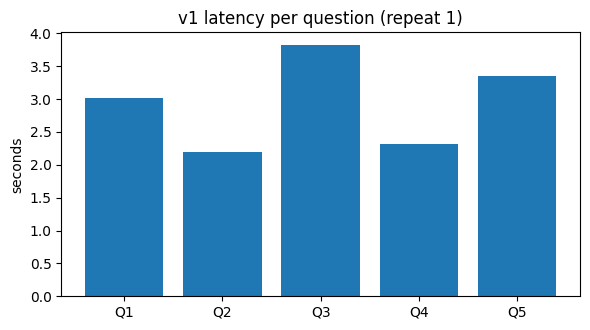

In [7]:
lat = v1["latency_seconds"]
lat_stats = pd.Series({"mean": lat.mean(), "median": lat.median(), "min": lat.min(),
                       "max": lat.max(), "std": lat.std(ddof=1)}, name="latency_seconds").round(3)
print(lat_stats.to_string())

slow = v1.loc[lat.idxmax()]
print(f"\nSlowest v1 request: {slow.question_id}, {slow.latency_seconds:.2f}s, {slow.output_tokens} output tokens")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(v1["question_id"], v1["latency_seconds"])
ax.set(title="v1 latency per question (repeat 1)", ylabel="seconds")
plt.tight_layout()
plt.show()

Observation

* **Spread:** the five v1 requests average 2.94 s (median 3.02 s), range 2.19 s to 3.82 s, standard deviation 0.69 s.
* **Slowest request:** Q3 (mlops scenario) at 3.82 s with 767 output tokens. It was not the longest answer (Q5 wrote 831 tokens in 3.36 s, against 767 tokens here), so output length does not explain it alone: network round-trip time and provider load at that moment also vary from call to call. So it is less to do with compute, more with network turnaround.
* Five requests are too few to say how much of this is the prompt and how much is chance, so now we measure it with repeats for cleaner result

#### How noisy is latency?

Each (version, question) pair was sent 3 times with identical input and `temperature = 0`, so any difference in latency between repeats is noise from the network and the provider, not from the prompt. The table gives mean, standard deviation and the 95th percentile (p95: the latency that 95% of requests stay under, which is what a service-level target is normally written against) for each version, plus the share of requests that met the assumed 2 s interactive target.

                mean_s  std_s  min_s  p95_s  max_s  sla_hit_rate
prompt_version                                                  
v1               2.948  0.760  2.095  4.005  4.426         0.000
v2               2.044  0.311  1.559  2.585  2.627         0.533
v3               1.311  0.639  1.012  2.155  3.565         0.933

Largest swing for identical input: ('v3', 'Q5') 2.6x between fastest and slowest repeat
Correlation (latency, output tokens): 0.86
Mean latency by repeat (s): {1: 2.15, 2: 1.97, 3: 2.19}


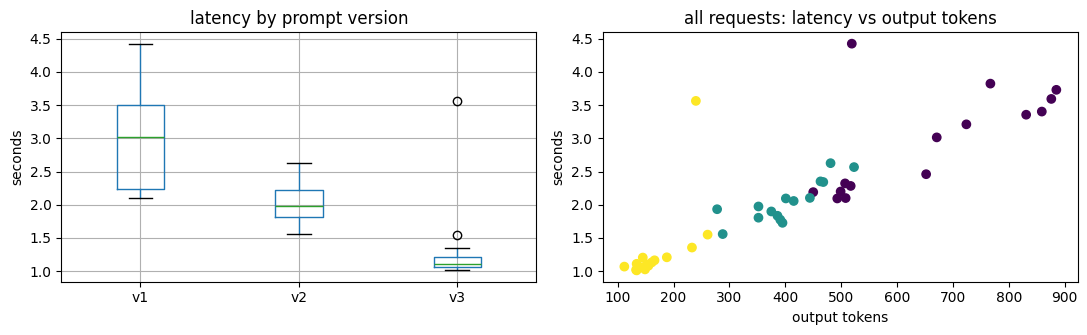

In [8]:
def p95(s):
    return float(np.percentile(s, 95))


noise = df.groupby("prompt_version").agg(
    mean_s=("latency_seconds", "mean"), std_s=("latency_seconds", "std"),
    min_s=("latency_seconds", "min"), p95_s=("latency_seconds", p95), max_s=("latency_seconds", "max"),
    sla_hit_rate=("latency_seconds", lambda s: (s <= SLA_SECONDS).mean()))
print(noise.round(3).to_string())

same_input = df.groupby(["prompt_version", "question_id"])["latency_seconds"].agg(["min", "max"])
same_input["max_over_min"] = same_input["max"] / same_input["min"]
print("\nLargest swing for identical input:", same_input["max_over_min"].idxmax(),
      f"{same_input['max_over_min'].max():.1f}x between fastest and slowest repeat")
print("Correlation (latency, output tokens): %.2f" % df["latency_seconds"].corr(df["output_tokens"]))
print("Mean latency by repeat (s):", df.groupby("repeat")["latency_seconds"].mean().round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
df.boxplot(column="latency_seconds", by="prompt_version", ax=axes[0])
axes[0].set(title="latency by prompt version", xlabel="", ylabel="seconds")
axes[1].scatter(df["output_tokens"], df["latency_seconds"], c=df["prompt_version"].map({"v1": 0, "v2": 1, "v3": 2}))
axes[1].set(title="all requests: latency vs output tokens", xlabel="output tokens", ylabel="seconds")
plt.suptitle("")
plt.tight_layout()
plt.show()

Observation

* **Ranking:** mean latency was v1 2.95 s, v2 2.04 s, v3 1.31 s. v3 had the lowest average, but the standard deviations (v1 0.76 s, v2 0.31 s, v3 0.64 s) show how much a single request can differ from it. Every gap is at least two standard errors (v1: 1.64 s slower, 6.4 standard errors; v2: 0.73 s slower, 4.0 standard errors), so the speed ordering is unlikely to be noise.
* **Tail:** p95 was v1 4.01 s, v2 2.59 s, v3 2.15 s. A service target should be written against p95, not the mean, because the slow requests are the ones users complain about.
* **Noise:** identical input took up to 2.6x longer on one repeat than another (v3 Q5). Output length closely tracks latency (correlation 0.86), so provider and network conditions add a large share on top of generation time.
* **Drift:** mean latency by repeat was repeat 1 2.15 s, repeat 2 1.97 s, repeat 3 2.19 s, so the provider's speed changed during the run itself. This is why the repeats are interleaved: a version that happened to run in a slow minute would otherwise look worse for no reason of its own.
* **Target:** the share of requests within 2 s was v1 0%, v2 53%, v3 93%. These absolute figures describe the provider at the time of this run. They should be re-measured at the time of deployment, not read off one run.

### Task-2: Count Tokens and Calculate Cost

Token counts are read from the `usage` field of each API response, not estimated. Cost uses the published per-million-token prices:

```
Input Cost   = Input Tokens  / 1,000,000 x Input Price per Million
Output Cost  = Output Tokens / 1,000,000 x Output Price per Million
Total Cost   = Input Cost + Output Cost
Monthly Cost = Average Cost per Request x 10,000
```

Pricing: Gemini 3.5 Flash-Lite, standard paid tier, 0.3 USD per 1M input and 2.5 USD per 1M output tokens, checked on 2026-11-03. The key used here is on the free tier, so the actual bill is zero; the figures are what the same usage would cost at published rates.

#### Tokens and cost per request

The table shows every question under every prompt version for the first repeat, which is the "per request" view the brief asks for. The full log with all repeats is in `outputs/latency_tokens_cost.csv`.

In [9]:
cost_table = df[df["repeat"] == 1][["question_id", "prompt_version", "input_tokens", "output_tokens",
                                    "total_tokens", "input_cost", "output_cost", "total_cost"]]
cost_table.sort_values(["prompt_version", "question_id"]).reset_index(drop=True)

,question_id,prompt_version,input_tokens,output_tokens,total_tokens,input_cost,output_cost,total_cost
0,Q1,v1,28,671,699,0.000008,0.001677,0.001686
1,Q2,v1,43,450,493,0.000013,0.001125,0.001138
2,Q3,v1,50,767,817,0.000015,0.001917,0.001932
3,Q4,v1,25,507,532,0.000008,0.001267,0.001275
4,Q5,v1,37,831,868,0.000011,0.002077,0.002089
5,Q1,v2,52,395,447,0.000016,0.000988,0.001003
6,Q2,v2,67,288,355,0.000020,0.000720,0.000740
7,Q3,v2,74,468,542,0.000022,0.001170,0.001192
8,Q4,v2,49,375,424,0.000015,0.000937,0.000952
9,Q5,v2,61,415,476,0.000018,0.001038,0.001056


#### Monthly projection for 10,000 requests

The brief's projection is the average cost per request times 10,000. The average here is taken over all 45 requests, which is steadier than a single run.

In [10]:
proj = df.groupby("prompt_version").agg(avg_input_tokens=("input_tokens", "mean"),
                                        avg_output_tokens=("output_tokens", "mean"),
                                        avg_cost_per_request=("total_cost", "mean"))
proj["projected_monthly_cost"] = proj["avg_cost_per_request"] * MONTHLY_REQUESTS
proj.round(6)

,avg_input_tokens,avg_output_tokens,avg_cost_per_request,projected_monthly_cost
prompt_version,,,,
v1,36.6,650.533333,0.001637,16.373133
v2,60.6,400.800000,0.001020,10.201800
v3,101.6,166.866667,0.000448,4.476467


#### Extra measures

Four extra measures turn the same log into business metrics: output tokens per second (how fast the model generates), cost per 1,000 answers (an easier unit than fractions of a cent), the share of the bill that is output tokens, and the average answer length and number of key points.

In [11]:
def summarize(d):
    g = d.groupby("prompt_version").agg(
        avg_latency_seconds=("latency_seconds", "mean"),
        avg_input_tokens=("input_tokens", "mean"),
        avg_output_tokens=("output_tokens", "mean"),
        avg_cost_per_request=("total_cost", "mean"),
        valid_json=("valid_json", "mean"),
        std_latency_seconds=("latency_seconds", "std"),
        p95_latency_seconds=("latency_seconds", p95),
        sla_hit_rate=("latency_seconds", lambda s: (s <= SLA_SECONDS).mean()),
        avg_tokens_per_second=("tokens_per_second", "mean"),
        avg_answer_words=("answer_words", "mean"),
        avg_key_points=("key_points", "mean"))
    g["cost_per_1k_requests"] = g["avg_cost_per_request"] * 1000
    return g.reset_index()


summary = summarize(df)
cost_sum = df.groupby("prompt_version")[["output_cost", "total_cost"]].sum()
share = cost_sum["output_cost"] / cost_sum["total_cost"]
extra = summary.set_index("prompt_version")[["avg_tokens_per_second", "cost_per_1k_requests",
                                              "avg_answer_words", "avg_key_points"]].assign(output_share_of_cost=share)
print(f"Output token price / input token price = {OUT_PRICE / IN_PRICE:.1f}x")
extra.round(4)

Output token price / input token price = 8.3x


,avg_tokens_per_second,cost_per_1k_requests,avg_answer_words,avg_key_points,output_share_of_cost
prompt_version,,,,,
v1,224.3714,1.6373,461.5333,NaN,0.9933
v2,196.3903,1.0202,291.2000,NaN,0.9822
v3,134.2923,0.4476,110.8667,4.0,0.9319


Result

* v1 costs 0.001637 USD per request, which projects to 16.37 USD for 10,000 requests a month; v2 projects to 10.20 USD; v3 projects to 4.48 USD.
* Output tokens are 93% to 99% of the spend, so v3 is cheaper even though it sends 2.8 times the input tokens of v1: it writes only 26% of the output.

#### Cost-optimization recommendation

**Shorten the responses.** Output tokens drive almost all of the cost, so controlling answer length gives the largest saving. Moving from the open-ended v1 to the constrained v3 cut output tokens by 74% and cost per request by 73% (0.001637 to 0.000448 USD), about 11.90 USD a month at 10,000 requests. A `max_tokens` cap on top of this prevents a rare long answer from inflating the bill.

Further options, in order of effort:
* Cache the stable prompt prefix (role and schema) if the provider supports prompt caching. This helps v3 most, since its input is the largest.
* Route simple, short questions to a smaller or cheaper model and keep the larger one for hard questions.

#### Scale and business view

The brief fixes 10,000 requests, but a decision about a real service depends on what happens at other volumes and against a latency target. The figures in this section combine measured averages with a few stated assumptions, so they are scenarios and not forecasts:

* **Volumes:** baseline (brief) 10,000, exam season 100,000, campus-wide 1,000,000 requests a month.
* **Latency target:** 2 s for an interactive chat answer.
* **Peak rate:** 5 requests per second at the busiest moment. By Little's law, the number of requests in flight is the arrival rate times the average latency, which is roughly how many concurrent connections the service must handle.

In [12]:
s = summary.set_index("prompt_version")
scale = pd.DataFrame({name: s["avg_cost_per_request"] * n for name, n in SCALE_VOLUMES.items()})
scale["cost_per_request"] = s["avg_cost_per_request"]
scale["concurrent_requests_at_peak"] = s["avg_latency_seconds"] * PEAK_RPS
print("Monthly cost (USD) by volume, plus cost per request and concurrency at peak")
scale.round(6)

Monthly cost (USD) by volume, plus cost per request and concurrency at peak


,Baseline (brief),Exam season,Campus-wide,cost_per_request,concurrent_requests_at_peak
prompt_version,,,,,
v1,16.373133,163.731333,1637.313333,0.001637,14.739233
v2,10.201800,102.018000,1020.180000,0.001020,10.218833
v3,4.476467,44.764667,447.646667,0.000448,6.555500


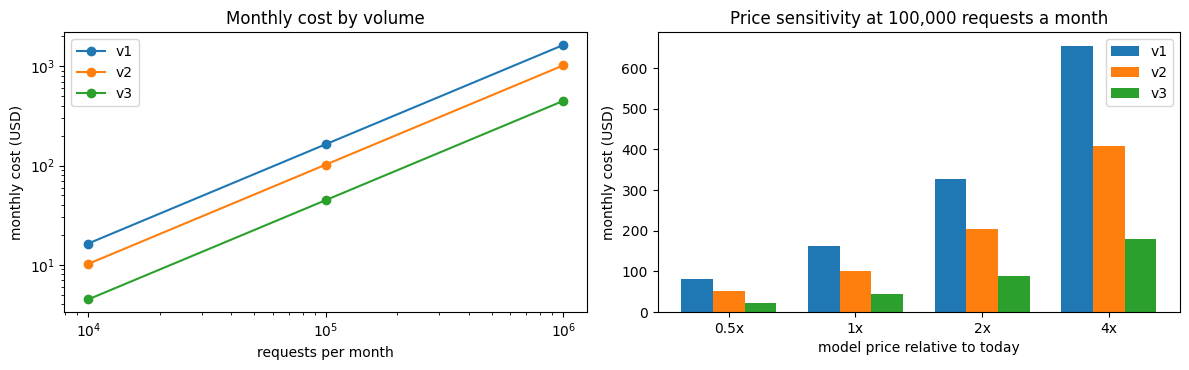

v3 stays cheaper than v1 unless the model it runs on costs more than 3.7x as much per token


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

volumes = list(SCALE_VOLUMES.values())
for v in s.index:
    axes[0].plot(volumes, [s.loc[v, "avg_cost_per_request"] * n for n in volumes], marker="o", label=v)
axes[0].set(xscale="log", yscale="log", xlabel="requests per month", ylabel="monthly cost (USD)",
            title="Monthly cost by volume")
axes[0].legend()

mid = list(SCALE_VOLUMES.values())[1]
width = 0.25
for i, v in enumerate(s.index):
    axes[1].bar(np.arange(len(PRICE_MULTIPLIERS)) + i * width,
                [s.loc[v, "avg_cost_per_request"] * m * mid for m in PRICE_MULTIPLIERS], width, label=v)
axes[1].set_xticks(np.arange(len(PRICE_MULTIPLIERS)) + width)
axes[1].set_xticklabels([f"{m}x" for m in PRICE_MULTIPLIERS])
axes[1].set(xlabel="model price relative to today", ylabel="monthly cost (USD)",
            title=f"Price sensitivity at {mid:,} requests a month")
axes[1].legend()
plt.tight_layout()
plt.show()

recommended = summary.sort_values(["valid_json", "avg_cost_per_request"],
                                  ascending=[False, True])["prompt_version"].iloc[0]
breakeven = s.loc["v1", "avg_cost_per_request"] / s.loc[recommended, "avg_cost_per_request"]
print(f"{recommended} stays cheaper than v1 unless the model it runs on costs more than {breakeven:.1f}x as much per token")

Observation

* **Scale:** cost grows in step with volume, so the gap between prompts grows with it. At 1,000,000 requests a month (campus-wide) v3 costs 448 USD against 1,637 USD for v1, a saving of 1,190 USD a month for answering the same questions. At 100,000 requests (exam season) the saving is 119 USD.
* **A prompt change is worth a cheaper model:** v3 runs at 73% lower cost than v1 on the same model. To lose that advantage, the model behind v3 would have to cost 3.7 times as much per token. Prompt design is therefore a cost lever on par with switching to a model that is several times cheaper, and it is free to try.
* **Capacity:** at 5 requests per second the service needs about v1 14.7, v2 10.2, v3 6.6 requests in flight. These use this run's average latency, which drifted during the run, so treat them as a shape and not a sizing. The point stands: slower and longer answers hold connections open, so output length also drives infrastructure, not just the token bill.
* **Caveat:** volumes, the target and the peak rate are assumptions. Replace them with real usage data before using these numbers to budget.

### Task-3: Prompt Versioning and MLflow Evaluation

MLflow's Prompt Registry stores prompts centrally with versions, commit messages and aliases. The plan is:
* register v1, v2 and v3 as three versions of one prompt, `eduassist-qa-prompt`;
* log one MLflow run per version in the experiment `eduassist_llmops_assignment` with the five required metrics, plus the extra measures from above;
* compare the versions and promote the best one by pointing the `production` alias at it.

#### Register the three prompt versions

Registration is idempotent: if a version with an identical template already exists it is reused, so re-running the notebook does not create duplicate versions. Each version gets a commit message that says what changed.

In [14]:
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
mlflow.set_experiment(EXPERIMENT)
client = MlflowClient()


def existing_version(template):
    v = 1
    while True:
        try:
            p = mlflow.genai.load_prompt(f"prompts:/{PROMPT_NAME}/{v}")
        except Exception:  # no such prompt or version yet
            return None
        if p.template == template:
            return p.version
        v += 1


versions = {}
for label, p in PROMPTS.items():
    found = existing_version(p["template"])
    if found:
        versions[label] = found
        continue
    reg = mlflow.genai.register_prompt(name=PROMPT_NAME, template=p["template"], commit_message=p["commit"],
                                       tags={"label": label, "style": p["style"]})
    versions[label] = reg.version

for label, v in versions.items():
    print(f"{label} -> registry version {v}: {PROMPTS[label]['commit']}")

v1 -> registry version 1: v1 Basic: bare instruction, no role, no format or audience guidance (baseline).
v2 -> registry version 2: v2 Structured: adds academic-assistant role and clear/concise/simple-language constraints.
v3 -> registry version 3: v3 JSON Output: adds strict JSON-only output with answer/confidence/key_points schema.


Result

* `eduassist-qa-prompt` now holds three versions (v1, v2, v3 as registry versions 1, 2, 3), each with its own commit message.

#### Prompt diff

The unified diff shows exactly what changed between versions, which is the point of versioning prompts instead of editing them in place. The diffs are also saved to `outputs/` for the submission, and the MLflow UI shows the same comparison with highlighting (screenshot further below).

In [15]:
def prompt_diff(a, b):
    lines = difflib.unified_diff(PROMPTS[a]["template"].splitlines(), PROMPTS[b]["template"].splitlines(),
                                 fromfile=f"prompt {a}", tofile=f"prompt {b}", lineterm="")
    return "\n".join(lines) + "\n"


for a, b in [("v1", "v2"), ("v2", "v3"), ("v1", "v3")]:
    (OUT / f"prompt_diff_{a}_{b}.txt").write_text(prompt_diff(a, b), encoding="utf-8")

print(prompt_diff("v2", "v3"))

--- prompt v2
+++ prompt v3
@@ -1,4 +1,10 @@
 You are an academic assistant.
-Answer the following student question in a clear, concise, and accurate manner.
-Use simple language suitable for undergraduate students.
+Answer the student question and return ONLY valid JSON.
+Do not include markdown, explanations outside JSON, or code fences.
+Use this exact JSON schema:
+{
+  "answer": "string",
+  "confidence": "high | medium | low",
+  "key_points": ["string"]
+}
 Question: {{question}}



Observation

* v1 to v2 adds a role and style constraints ("clear, concise, accurate", "undergraduate students") without changing the task.
* v2 to v3 keeps the role and adds the output contract: JSON only, no markdown or code fences, and the exact schema.

#### Log one MLflow run per prompt version

Each run records the model, pricing and prompt version as parameters, and the five required metrics: `avg_latency_seconds`, `avg_input_tokens`, `avg_output_tokens`, `avg_cost_per_request` and `valid_json`. For v3, `valid_json` is valid responses divided by total responses; it is computed the same way for v1 and v2 so the three can be compared. The averages cover all 15 requests per version. The extra measures (latency standard deviation and p95, target hit rate, tokens per second, cost per 1,000 requests) are logged alongside. The per-request responses are attached to each run as a table, and a rerun replaces the earlier run of the same name instead of piling up duplicates.

In [16]:
required = ["avg_latency_seconds", "avg_input_tokens", "avg_output_tokens", "avg_cost_per_request", "valid_json"]
optional = ["std_latency_seconds", "p95_latency_seconds", "sla_hit_rate", "avg_tokens_per_second",
            "avg_answer_words", "cost_per_1k_requests", "avg_key_points"]

exp_id = mlflow.get_experiment_by_name(EXPERIMENT).experiment_id
for _, row in summary.iterrows():
    label = row["prompt_version"]
    for old in client.search_runs([exp_id], f"tags.mlflow.runName = 'prompt_{label}'"):
        client.delete_run(old.info.run_id)
    sub = df[df["prompt_version"] == label]
    with mlflow.start_run(run_name=f"prompt_{label}"):
        mlflow.log_params({"prompt_name": PROMPT_NAME, "prompt_label": label,
                           "prompt_registry_version": versions[label], "model": MODEL,
                           "api_version": API_VERSION, "temperature": TEMPERATURE,
                           "input_price_per_m": IN_PRICE, "output_price_per_m": OUT_PRICE,
                           "pricing_date": PRICING_DATE, "currency": CURRENCY,
                           "num_questions": sub["question_id"].nunique(), "repeats": REPEATS,
                           "num_requests": len(sub), "sla_seconds": SLA_SECONDS})
        mlflow.log_metrics({k: float(row[k]) for k in required})
        mlflow.log_metrics({k: float(row[k]) for k in optional if pd.notna(row[k])})
        mlflow.log_table(sub.drop(columns=["error"]), artifact_file="responses.json")
        for a, b in [("v1", "v2"), ("v2", "v3"), ("v1", "v3")]:
            mlflow.log_artifact(str(OUT / f"prompt_diff_{a}_{b}.txt"), artifact_path="prompt_diffs")
    print(f"logged run prompt_{label}")

logged run prompt_v1


logged run prompt_v2


logged run prompt_v3


#### Compare the versions and promote the best one

Selection rule, in order: highest `valid_json` first, because EduAssist's product contract is strict JSON and an answer a parser rejects is unusable; then lowest cost per request; then lowest latency. The winner gets the `production` alias, which lets the application load the current prompt by alias without a code change and roll back by moving the alias.

In [17]:
ranked = summary.sort_values(["valid_json", "avg_cost_per_request", "avg_latency_seconds"],
                             ascending=[False, True, True])
best = ranked.iloc[0]["prompt_version"]
client.set_prompt_alias(PROMPT_NAME, "production", versions[best])

comparison = summary.copy()
comparison["recommended"] = comparison["prompt_version"].map(lambda v: "Yes" if v == best else "No")
comparison.to_csv(EVAL_CSV, index=False)

print(f"Promoted {best} (registry version {versions[best]}) to alias 'production'")
comparison[["prompt_version"] + required + ["recommended"]].rename(columns={
    "prompt_version": "Prompt Version", "avg_latency_seconds": "Avg Latency (s)",
    "avg_input_tokens": "Avg Input Tokens", "avg_output_tokens": "Avg Output Tokens",
    "avg_cost_per_request": "Avg Cost (USD)", "valid_json": "Valid JSON Rate",
    "recommended": "Recommended?"}).round(6)

Promoted v3 (registry version 3) to alias 'production'


,Prompt Version,Avg Latency (s),Avg Input Tokens,Avg Output Tokens,Avg Cost (USD),Valid JSON Rate,Recommended?
0,v1,2.947847,36.6,650.533333,0.001637,0.0,No
1,v2,2.043767,60.6,400.800000,0.001020,0.0,No
2,v3,1.311100,101.6,166.866667,0.000448,1.0,Yes


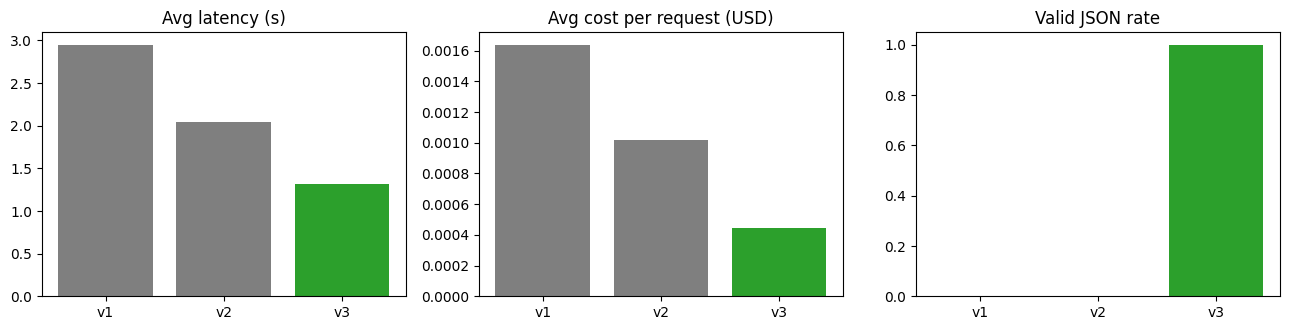

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, title in zip(axes, ["avg_latency_seconds", "avg_cost_per_request", "valid_json"],
                          ["Avg latency (s)", "Avg cost per request (USD)", "Valid JSON rate"]):
    ax.bar(comparison["prompt_version"], comparison[col],
           color=["tab:green" if r == "Yes" else "tab:gray" for r in comparison["recommended"]])
    ax.set_title(title)
plt.tight_layout()
plt.show()

Result

* v3 is recommended and now carries the `production` alias; valid JSON rate is v1 0%, v2 0%, v3 100%. The table is saved to `outputs/prompt_evaluation_results.csv`.
* v3 also has the lowest average latency (1.31 s vs 2.95 s and 2.04 s) and the lowest cost per request (0.000448 vs 0.001637 and 0.001020 USD).

#### Check the production alias

Load the prompt through the alias exactly as an application would, fill in a question and confirm the model's reply parses against the schema.

In [19]:
prod = mlflow.genai.load_prompt(f"prompts:/{PROMPT_NAME}@production")
print("production -> version", prod.version)
print("commit message:", prod.commit_message)

reply = call_llm(render(prod.template, QUESTIONS["Q1"]))
parsed = json.loads(reply["response_text"])
print("\nvalid against schema:", is_valid_json(reply["response_text"]))
print("confidence :", parsed["confidence"])
print("key_points :", *parsed["key_points"], sep="\n  - ")

production -> version 3
commit message: v3 JSON Output: adds strict JSON-only output with answer/confidence/key_points schema.



valid against schema: True
confidence : high
key_points :
  - Calculates the harmonic mean of precision and recall
  - Accounts for both false positives and false negatives
  - Preferred over accuracy for imbalanced datasets
  - Useful when false positives and false negatives have different costs


Result

* `production` resolves to the promoted v3 prompt and its commit message, and a live call through the alias returned JSON that passes the schema check.
* This cell makes one extra API call, so the answer text differs slightly from the saved log.

#### MLflow UI evidence

Start the UI with `mlflow ui --backend-store-uri sqlite:///mlflow.db` and open http://127.0.0.1:5000. The screenshots below were taken from it.

**Experiment `eduassist_llmops_assignment`: three runs and their metrics**

![MLFlow listing page](mlflow_screens/listing_page.png)

![experiment runs and metrics](mlflow_screens/eval_list_page.png)

**Run metrics for `prompt_v3`**

![run metrics](mlflow_screens/v3_prompt_overview.png)

**Prompt Registry: versions 1, 2 and 3**

![prompt registry](mlflow_screens/qa-prompt.png)

**Prompt diff, v3 against v2**

![prompt diff](mlflow_screens/compare_prompts.png)

**`production` alias on version 3**

![production alias](mlflow_screens/production_alias.png)

#### Promotion justification

We promoted **v3** to the `production` alias.

**JSON validity (decisive).** EduAssist's product contract is strict JSON. v3 returned valid, schema-conforming JSON for 15 of 15 requests (100%), while v1 and v2 scored 0% because they answer in free-form prose and were never asked for JSON. Downstream code can parse v3 directly; the others would need a second model call or fragile text parsing.

**Latency.** v3 averages 1.31 s, against v1 2.95 s, v2 2.04 s (p95 for v3 is 2.15 s). Every gap is at least two standard errors (v1: 1.64 s slower, 6.4 standard errors; v2: 0.73 s slower, 4.0 standard errors), so the speed ordering is unlikely to be noise. It also writes the fewest tokens, which is the lasting reason to expect it to be quicker, since generation time grows with output length.

**Tokens.** v3 uses more input tokens (101.6 vs v1 36.6, v2 60.6) because it carries the schema, but far fewer output tokens (166.9 vs v1 650.5, v2 400.8). Output tokens are the expensive side (8.3x the input price), so the extra input is a good trade.

**Cost and scale.** Cost per request falls to 0.000448 USD, against v1 0.001637, v2 0.001020, about 73% below v1. At 10,000 requests a month this projects to 4.48 USD versus v1 16.37, v2 10.20 USD, and the gap widens linearly with volume: 1,190 USD a month at 1,000,000 requests.

**Quality.** Answer correctness was not scored automatically in this experiment. v3 keeps the academic-assistant role and adds a confidence level and key points, which make answers easier for a human to review.

**Limitations.** Five questions is a small sample, latency depends on provider load at the time of the run, and the scale figures rest on stated assumptions. A larger evaluation set with quality scoring should confirm the choice before wide rollout. The alias makes rollback instant: pointing `production` back at v2 needs no code change.

#### Why we built it this way

| Decision | What | Why |
|---|---|---|
| Questions from our own modules | 5 questions across 5 categories | realistic mix of answer lengths, and not the generic set others will use |
| Same questions for all versions | 3 versions x 5 questions | differences come from the prompt, not the input |
| 3 interleaved repeats | 45 requests in total | measures latency noise, and a slow period cannot favour one version |
| `temperature = 0` | fixed for every call | reduces run-to-run variation in length and wording |
| Token counts from `usage` | read from each API response | exact billing basis, not an estimate |
| p95 and target hit rate | beside the mean | a service is judged on its slow requests, not its average |
| Scale scenarios | 3 volumes, latency target, peak rate | a prompt decision is a cost and capacity decision at real volume |
| Strict `valid_json` | raw text must parse and match the schema | fences or prose would break a real parser |
| One prompt, three versions | `eduassist-qa-prompt` v1 to v3 | gives a real diff and one alias to move |
| Promote by alias | `production` -> best version | deploy and roll back without changing code |
| Key from environment | `.env`, git-ignored | secrets never reach the notebook or the ZIP |

#### Reproducibility checks

Confirm the saved log is complete and internally consistent: all requests succeeded, costs recompute exactly from the token counts and prices, and the alias points to the recommended version.

In [20]:
log = pd.read_csv(CALLS_CSV)
recomputed = log["input_tokens"] / 1e6 * IN_PRICE + log["output_tokens"] / 1e6 * OUT_PRICE

print("Rows                     :", len(log), "(expected 45)")
print("All requests succeeded   :", bool((log["status"] == "success").all()))
print("Costs match tokens x price:", bool((recomputed - log["total_cost"]).abs().max() < 1e-12))
print("Tokens add up            :", bool((log["input_tokens"] + log["output_tokens"] == log["total_tokens"]).all()))
print("Alias -> recommended     :", mlflow.genai.load_prompt(f"prompts:/{PROMPT_NAME}@production").version == versions[best])
print("Prompt versions in registry:", sorted(versions.values()))

Rows                     : 45 (expected 45)
All requests succeeded   : True
Costs match tokens x price: True
Tokens add up            : True
Alias -> recommended     : True
Prompt versions in registry: [1, 2, 3]


Result

* All 45 rows succeeded, costs recompute exactly from tokens x price, and tokens add up. The `production` alias points to v3 and the registry holds exactly versions 1, 2 and 3.
* Token counts, costs and JSON validity depend on the prompt and should reproduce closely. Latency, p95 and target hit rate depend on provider load and will differ on a new run.


Thus, we measured the latency of five academic questions across 45 requests (3 repeats x 3 prompt versions), turned the token counts into cost per request and a monthly projection, and versioned three prompts in the MLflow Prompt Registry, comparing them on latency, tokens, cost and JSON validity before promoting the best one through the production alias.

We learned that prompt wording is a cost and latency lever, not only a quality one: the strict-JSON prompt (v3) sent more input tokens but wrote about 74% fewer output tokens, which cut cost by about 73% (4.48 vs 16.37 USD a month at 10,000 requests) and mean latency from 2.95 s to 1.31 s, and it was the only version that returned valid JSON. We also learned that latency is noisy and should be judged on repeats and p95 rather than a single run, and that an alias turns promotion and rollback into a metadata change, not a code change.